# Verificación de cifras significativas en `fcst_temp_c` / `fcst_windspeed_kmh`

Chequeo puntual, fuera del pipeline numerado: en `ETL/merge_data.py` (función `parse_pronosticos`), la temperatura y
el viento del pronóstico se convierten de unidades imperiales con `round(..., 2)`:

```python
"fcst_temp_c",
when(col("fcst_temp_unit") == "F", round((col("fcst_temp_raw") - 32) * 5/9, 2))
.otherwise(col("fcst_temp_raw"))
...
"fcst_windspeed_kmh",
round(col("fcst_wind_mph") * 1.60934, 2)
```

La API del NWS reporta `fcst_temp_raw` en **grados Fahrenheit enteros** y `fcst_wind_mph` en **mph enteros**. Redondear
el resultado de la conversión a 2 decimales no agrega precisión real: sólo hace que un número con resolución de 1
unidad en la escala original *se vea* como si tuviera centésimas de °C o km/h. Si eso es cierto, `fcst_temp_c` y
`fcst_windspeed_kmh` sólo pueden caer en una grilla discreta de valores (espaciada `5/9 °C` y `1.60934 km/h`
respectivamente), mientras que `obs_temp_c`/`obs_windspeed_kmh` (que no pasan por esa conversión) deberían verse mucho
más finos.

Este notebook corre esa verificación sobre `mediciones_limpias.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils import AZUL, NARANJA, GRIS_TEXTO, aplicar_estilo

OUT = '../data/out/verificacion_cifras_significativas/'
aplicar_estilo()
figuras = {}

mp = pd.read_csv('../data/processed/mediciones_limpias.csv')
print(f'{len(mp):,} filas cargadas de mediciones_limpias.csv')

130,562 filas cargadas de mediciones_limpias.csv


## 1. Temperatura: ¿`fcst_temp_c` es un entero en °F disfrazado?

Test de grilla: si el dato original era entero en °F, entonces `fcst_temp_c / (5/9) módulo 1` debería concentrarse cerca de 0 o de 1 (resto casi nulo), en vez de distribuirse uniforme entre 0 y 1 como pasaría con un dato continuo.

In [2]:
PASO_F = 5 / 9  # °C equivalentes a 1 °F

fcst_t = mp['fcst_temp_c'].dropna()
obs_t = mp['obs_temp_c'].dropna()

resto_fcst_t = (fcst_t / PASO_F) % 1
resto_obs_t = (obs_t / PASO_F) % 1

print('--- fcst_temp_c: resto mod (5/9 °C), valores más frecuentes ---')
print(resto_fcst_t.round(3).value_counts().head(10))
print()
print('--- obs_temp_c: resto mod (5/9 °C), valores más frecuentes ---')
print(resto_obs_t.round(3).value_counts().head(10))
print()
print(f"fcst_temp_c: {fcst_t.nunique()} valores únicos en todo el dataset")
print(f"obs_temp_c:  {obs_t.nunique()} valores únicos en todo el dataset")
print(f"fcst_temp_c: {fcst_t[(fcst_t >= 10) & (fcst_t < 20)].nunique()} valores únicos en el rango [10, 20) °C")
print(f"obs_temp_c:  {obs_t[(obs_t >= 10) & (obs_t < 20)].nunique()} valores únicos en el rango [10, 20) °C")

--- fcst_temp_c: resto mod (5/9 °C), valores más frecuentes ---
fcst_temp_c
0.996    15132
0.998    14927
0.004    14896
0.000    14728
0.002    14681
0.994    14197
0.006    14060
0.008    13994
0.992    13940
Name: count, dtype: int64

--- obs_temp_c: resto mod (5/9 °C), valores más frecuentes ---
obs_temp_c
0.400    15606
0.600    15518
0.800    15371
0.200    14920
0.000    12651
0.996     1490
0.998     1461
0.992     1423
0.008     1416
0.994     1359
Name: count, dtype: int64

fcst_temp_c: 76 valores únicos en todo el dataset
obs_temp_c:  1841 valores únicos en todo el dataset
fcst_temp_c: 18 valores únicos en el rango [10, 20) °C
obs_temp_c:  752 valores únicos en el rango [10, 20) °C


**Resultado**: en `fcst_temp_c` casi toda la masa del resto cae en `0.99x`/`0.00x` (restos ≈0, es decir múltiplos
casi exactos de 5/9 °C) -la firma esperada de un entero en °F convertido. `obs_temp_c` no muestra esa concentración
con la misma fuerza y tiene **1841 valores únicos en todo el dataset contra sólo 76 de `fcst_temp_c`**, y en la
ventana angosta [10, 20) °C la diferencia es aún más marcada: **752 vs. 18**. Confirma la hipótesis: `fcst_temp_c`
tiene la resolución real de un grado Fahrenheit entero (~0.56 °C de paso), aunque se almacene con 2 decimales.

## 2. Viento: ¿`fcst_windspeed_kmh` es un entero en mph disfrazado?

Mismo test, con el factor de conversión mph → km/h (`1.60934`).

In [3]:
PASO_MPH = 1.60934  # km/h equivalentes a 1 mph

fcst_w = mp['fcst_windspeed_kmh'].dropna()
obs_w = mp['obs_windspeed_kmh'].dropna()

resto_fcst_w = (fcst_w / PASO_MPH) % 1
resto_obs_w = (obs_w / PASO_MPH) % 1

print('--- fcst_windspeed_kmh: resto mod (1.60934 km/h), valores más frecuentes ---')
print(resto_fcst_w.round(3).value_counts().head(8))
print()
print('--- obs_windspeed_kmh: resto mod (1.60934 km/h), valores más frecuentes ---')
print(resto_obs_w.round(3).value_counts().head(8))
print()
print(f"fcst_windspeed_kmh: {fcst_w.nunique()} valores únicos en todo el dataset")
print(f"obs_windspeed_kmh:  {obs_w.nunique()} valores únicos en todo el dataset")
print(f"fcst_windspeed_kmh: {fcst_w[(fcst_w >= 0) & (fcst_w < 20)].nunique()} valores únicos en el rango [0, 20) km/h")
print(f"obs_windspeed_kmh:  {obs_w[(obs_w >= 0) & (obs_w < 20)].nunique()} valores únicos en el rango [0, 20) km/h")

--- fcst_windspeed_kmh: resto mod (1.60934 km/h), valores más frecuentes ---
fcst_windspeed_kmh
0.002    45809
0.000    24931
0.998    19549
0.997    10407
0.001    10114
1.000     8028
0.003     6556
0.999     5161
Name: count, dtype: int64

--- obs_windspeed_kmh: resto mod (1.60934 km/h), valores más frecuentes ---
obs_windspeed_kmh
0.000    27570
0.053     8584
0.698     5930
0.816     5913
0.355     5386
0.935     5219
0.608     5191
0.749     5177
Name: count, dtype: int64

fcst_windspeed_kmh: 36 valores únicos en todo el dataset
obs_windspeed_kmh:  698 valores únicos en todo el dataset
fcst_windspeed_kmh: 11 valores únicos en el rango [0, 20) km/h
obs_windspeed_kmh:  525 valores únicos en el rango [0, 20) km/h


**Resultado**: mismo patrón, incluso más marcado. `fcst_windspeed_kmh` tiene sólo **36 valores únicos en todo el
dataset** (11 en [0, 20) km/h) contra **698** de `obs_windspeed_kmh` (525 en esa misma ventana), y el resto mod
1.60934 se concentra con fuerza en 0/1. Confirma que `fcst_wind_mph` también era un entero en mph.

## 3. Visualización: histograma fino (el "peine")

Con bins de 0.1 °C debería verse el pronóstico como picos regulares (peine) y la observación como una distribución más continua.

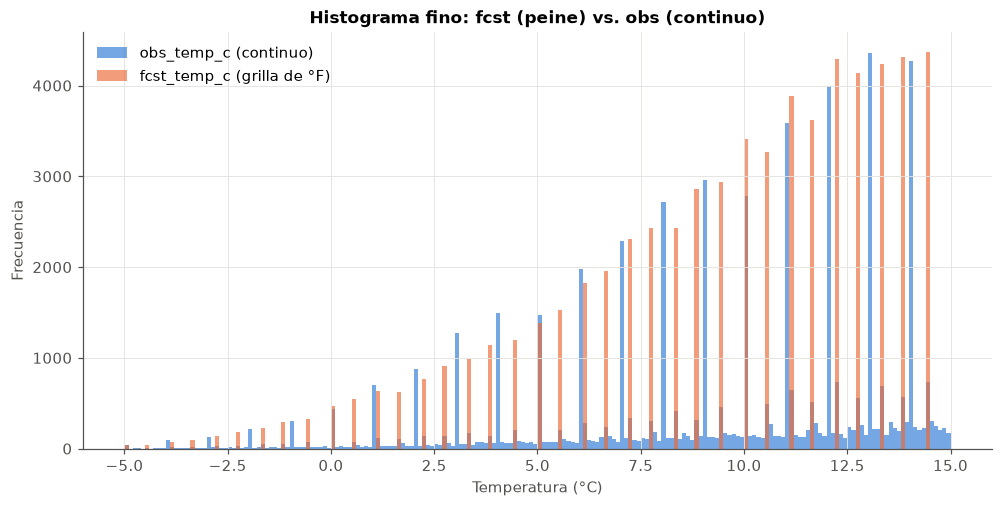

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
bins = np.arange(-5, 15.01, 0.1)
ax.hist(obs_t[(obs_t >= -5) & (obs_t < 15)], bins=bins, color=AZUL, alpha=0.65, label='obs_temp_c (continuo)')
ax.hist(fcst_t[(fcst_t >= -5) & (fcst_t < 15)], bins=bins, color=NARANJA, alpha=0.65, label='fcst_temp_c (grilla de °F)')
ax.set(xlabel='Temperatura (°C)', ylabel='Frecuencia', title='Histograma fino: fcst (peine) vs. obs (continuo)')
ax.legend(frameon=False)
figuras['01_histograma_peine_temp'] = fig
plt.show()

## 4. ¿El error del pronóstico hereda el patrón?

`error_temp_c = fcst_temp_c - obs_temp_c`: como un término es una grilla gruesa y el otro es casi continuo, interesa ver cuánto sobrevive el patrón en la resta.

In [5]:
err = mp['error_temp_c'].dropna()
resto_err = (err / PASO_F) % 1

print(f"error_temp_c: {err.nunique()} valores únicos (vs. {fcst_t.nunique()} de fcst_temp_c y {obs_t.nunique()} de obs_temp_c)")
print()
print('--- error_temp_c: resto mod (5/9 °C), valores más frecuentes ---')
print(resto_err.round(3).value_counts().head(10))
print()
print(err.describe().round(3))

error_temp_c: 3335 valores únicos (vs. 76 de fcst_temp_c y 1841 de obs_temp_c)

--- error_temp_c: resto mod (5/9 °C), valores más frecuentes ---
error_temp_c
0.000    3164
0.002    2689
0.998    2409
0.992    2361
0.008    2130
0.994    2122
0.596    2085
0.396    2080
0.604    2077
0.398    2070
Name: count, dtype: int64

count    121790.000
mean          0.002
std           1.883
min          -9.910
25%          -1.220
50%           0.000
75%           1.220
max           8.780
Name: error_temp_c, dtype: float64


**Resultado**: `error_temp_c` tiene 3335 valores únicos -mucho más que los 76 de `fcst_temp_c`, pero muy por debajo
de los 1841 de `obs_temp_c`-. El resto mod 5/9 sigue mostrando algo de concentración cerca de 0/1 (aunque mucho más
repartida que en `fcst_temp_c` solo), porque la parte continua de `obs_temp_c` sí logra "rellenar" bastante la
grilla gruesa del pronóstico al restarlo, pero no la borra del todo.

## 5. Conclusión

Sí hay un problema de cifras significativas, acotado a las dos columnas que pasan por conversión de unidades en
`ETL/merge_data.py`:

- **`fcst_temp_c`** (desde °F entero) y **`fcst_windspeed_kmh`** (desde mph entero) tienen una resolución real de
  ~0.56 °C y ~1.61 km/h respectivamente -el `round(..., 2)` posterior a la conversión no agrega precisión, sólo
  maquilla un dato de baja resolución con apariencia de 2 decimales.
- **`obs_temp_c`** y **`obs_windspeed_kmh`** (no pasan por esa conversión) tienen resolución muchísimo más fina
  (1841 y 698 valores únicos respectivamente, contra 76 y 36 del lado del pronóstico).
- El impacto sobre `error_<variable>` (el target real de los modelos, ver `7_modelado_global.ipynb`) es parcial: el
  lado de la observación "difumina" bastante la grilla gruesa del pronóstico, pero no la elimina -el error conserva
  menos valores únicos de los que tendría si ambos lados fueran continuos.
- No invalida los resultados existentes (MAE/RMSE/MASE reportados en `6_baselines_globales.ipynb` y
  `7_modelado_global.ipynb` siguen siendo correctos: están calculados sobre los datos tal como son, no sobre un
  supuesto de precisión que no existe), pero sí es una advertencia a tener en cuenta:
  - Reportar `fcst_temp_c`/`fcst_windspeed_kmh` con 2 decimales en tablas o gráficos sugiere una precisión que la
    fuente no tiene -redondear a 1 decimal (o directamente a la resolución real, ~0.6 °C) sería más honesto.
  - Cualquier diagnóstico fino sobre la distribución del error (colas, modas, ACF de alta frecuencia en
    `3_analisis_temporal.ipynb`) puede tener una componente de ruido de cuantización que no es variabilidad
    climática real, sino un artefacto de la conversión de unidades del pronóstico.

In [6]:
import os

os.makedirs(OUT, exist_ok=True)
for nombre, fig in figuras.items():
    fig.savefig(OUT + f'{nombre}.png', dpi=300, bbox_inches='tight', facecolor='white')
print(f'Guardado(s) {len(figuras)} gráfico(s) en {OUT}')

Guardado(s) 1 gráfico(s) en ../data/out/verificacion_cifras_significativas/
